# ASMSA v2 &mdash; Metadynamics

&#8592; [PLUMED export](05-plumed.ipynb) &nbsp;|&nbsp; [Analysis](07-analysis.ipynb) &#8594;

| | |
|---|---|
| **What it does** | Solvate, equilibrate, then run metadynamics biased along the learned collective variables, and compute free energies. |
| **Typical runtime** | hours to days for the production run |
| **Needs** | <code>plumed.dat</code> and the CV model from <a href='05-plumed.ipynb'>05-plumed</a>; <b>GROMACS and PLUMED installed</b> |
| **Produces** | <code>HILLS</code>, <code>COLVAR</code>, <code>md.xtc</code>, a free-energy surface |

---

This is the only notebook that needs external binaries. Without them it runs in
**dry-run mode**: every command is printed instead of executed, so the protocol can be
read and the exact shell script exported for a cluster, and the analysis section still
works on any `COLVAR`/`HILLS` files you bring back.

Your PLUMED build must have the **pytorch module enabled**, including the
`PYTORCH_MODEL` action used by ASMSA.

> *Note on v1:* v1 submitted these as Kubernetes jobs on one specific cluster, which made
the notebook unusable elsewhere. Execution here goes through a swappable runner, and
the long production run is detached so the kernel stays free for the analysis cells.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

import asmsa_v2 as asmsa
from asmsa_v2.md import (
    Gromacs, PreparationProtocol, check_environment,
    fes_convergence, hill_height_decay, kT, ns_to_steps,
    read_colvar, read_hills, reweight_fes, reweight_weights, sum_hills,
)
from asmsa_v2.viz import use_asmsa_style

use_asmsa_style()
project = asmsa.Project.load('run')
md_dir = project.dir('md')
print('simulation directory:', md_dir)

simulation directory: /home/tedeschg/prj/ASMSA_v2/notebooks/run/04-md


## 1. Environment

**What to look for:** `gmx` present, `plumed` present, and
`plumed pytorch module: enabled`. If `PYTORCH_MODEL` is unavailable, rebuild PLUMED with
`--enable-modules=pytorch` and LibTorch available.

In [2]:
import os

plumed_prefix = "/software/plumed-install"
libtorch_prefix = "/software/libtorch-2.5.1/libtorch"

os.environ["PLUMED_PREFIX"] = plumed_prefix
os.environ["LIBTORCH"] = libtorch_prefix
os.environ["PLUMED_KERNEL"] = f"{plumed_prefix}/lib/libplumedKernel.so"
os.environ["PATH"] = os.pathsep.join([
    "/software/gromacs-2026.3-plumed/bin",
    f"{plumed_prefix}/bin",
    os.environ["PATH"],
])
os.environ["LD_LIBRARY_PATH"] = os.pathsep.join(
    path for path in [
        f"{plumed_prefix}/lib",
        f"{libtorch_prefix}/lib",
        os.environ.get("LD_LIBRARY_PATH", ""),
    ] if path
)

In [3]:
env = check_environment()
for tool, version in env.items():
    print(f'  {tool:<24} {version}')

HAVE_GMX = 'NOT FOUND' not in env.get('gmx', 'NOT FOUND')
HAVE_PLUMED = 'NOT FOUND' not in env.get('plumed', 'NOT FOUND')
HAVE_PLUMED_PYTORCH = env.get('plumed pytorch module') == 'enabled'
DRY_RUN = not HAVE_GMX

if DRY_RUN:
    print('\n>>> DRY-RUN MODE: commands are printed, not executed.')
if HAVE_GMX and (not HAVE_PLUMED or not HAVE_PLUMED_PYTORCH):
    print('\n>>> Production metadynamics requires PLUMED with the',
          'PYTORCH_MODEL action enabled.')

  gmx                      2026.3
  plumed                   2.11
  plumed executable        /software/plumed-install/bin/plumed
  plumed pytorch module    enabled


In [4]:
# Resources for the production run. For proteins under ~50 residues more than one
# MPI rank rarely helps; a GPU starts to pay off around 15-20 residues.
OMP_THREADS = 4
GPU_ID = None          # e.g. '0' to pin a GPU

gmx = Gromacs(md_dir, dry_run=DRY_RUN)
if HAVE_GMX:
    print(gmx.version())

$ gmx --version   [log: gmx---version-1793454572.log]
GROMACS version:     2026.3


## 2. Stage the inputs

The simulation needs the solute coordinates and topology from
[02-prepare](02-prepare.ipynb), plus the CV model and `plumed.dat` from
[05-plumed](05-plumed.ipynb). `plumed.dat` refers to the model by bare filename, so it
must sit in this directory.

In [5]:
import shutil

needed = [project.gro, project.topol]
optional = ['posre.itp']

missing = []
for name in needed:
    src = project.root / name
    if src.exists():
        shutil.copy2(src, md_dir / src.name)
    else:
        missing.append(name)
for name in optional:
    src = project.root / name
    if src.exists():
        shutil.copy2(src, md_dir / src.name)

have_plumed_dat = project.plumed_dat.exists()
have_cv_model = (md_dir / f'{project.cv_stem}-plumed.pt').exists()

print(f'plumed.dat present : {have_plumed_dat}')
print(f'CV model present   : {have_cv_model}')
if missing:
    print(f'\nMISSING: {missing}')
    print('Run pdb2gmx in 02-prepare.ipynb (needs GROMACS) before continuing.')

for f in sorted(md_dir.iterdir()):
    print(f'  {f.name}')

plumed.dat present : True
CV model present   : True
  cv-norm-batch.pt
  cv-norm-plumed.pt
  logs
  plumed-driver.dat
  plumed.dat
  posre.itp
  trpcage.gro
  trpcage.top


## 3. The protocol

The standard solvated-protein sequence, unchanged from v1: box, solvate, neutralize,
minimize, NVT, NPT, production.

Each step is its own cell so you can inspect the result before continuing, and **each
step skips itself if its output already exists** &mdash; so re-running a cell after a
kernel restart costs nothing instead of redoing a minimization. Pass `force=True` to
the protocol to redo a step deliberately.

All `.mdp` files are generated from physical time units in one place, so the timestep,
temperature and output stride cannot silently disagree between stages. v1 asked you to
pick a production length from a commented list of magic step counts
(`mdsteps=250000000  # 500 ns`), which goes wrong the moment `dt` changes.

In [6]:
protocol = PreparationProtocol(
    workdir=md_dir,
    base=project.name,
    gro=project.gro,
    topol=project.topol,
    gmx=gmx,
    box_nm=project.box_nm,
    temperature=project.temperature,
    pressure=project.pressure,
    dt=project.dt,
    force=False,
)

protocol.write_mdps(
    production_ns=project.production_ns,
    equil_nvt_ps=100.0,
    equil_npt_ps=100.0,
)
protocol

  wrote 5 mdp files; production = 100.0 ns = 50000000 steps


·,topology (full) trpcage-full.top
·,box trpcage-box.gro
·,solvated trpcage-solv.gro
·,neutralized trpcage-ions.gro
·,minimized em.gro
·,NVT nvt.gro
·,NPT npt.gro
·,production tpr md.tpr
·,production traj md.xtc
·,HILLS HILLS


In [7]:
protocol.prepare_topology_copy()   # solvate/genion edit a copy, not the pdb2gmx output
protocol.make_box()
protocol.solvate()
protocol.add_ions()

  trpcage.top -> trpcage-full.top
$ gmx editconf -f trpcage.gro -o trpcage-box.gro -c -d 1.2 -bt dodecahedron   [log: gmx-editconf-1793454579.log]
$ gmx solvate -cp trpcage-box.gro -cs spc216.gro -o trpcage-solv.gro -p trpcage-full.top   [log: gmx-solvate-1793454579.log]
$ gmx grompp -f ions.mdp -c trpcage-solv.gro -p trpcage-full.top -o ions.tpr -maxwarn 2   [log: gmx-grompp-1793454579.log]
$ gmx genion -s ions.tpr -o trpcage-ions.gro -p trpcage-full.top -pname NA -nname CL -neutral  <<< 'SOL\n'   [log: gmx-genion-1793454579.log]


'trpcage-ions.gro'

### Energy minimization

Removes bad contacts introduced by placing solvent. Cheap; runs in the foreground.

In [8]:
protocol.minimize(background=False)

$ gmx grompp -f minim.mdp -c trpcage-ions.gro -p trpcage-full.top -o em.tpr -maxwarn 2   [log: gmx-grompp-1793454582.log]
$ gmx mdrun -deffnm em   [log: gmx-mdrun-1793454582.log]


### Equilibration

NVT then NPT, both with the solute position-restrained so the solvent relaxes around a
fixed structure. These run **detached** &mdash; re-run the status cell until each is done
rather than blocking the kernel.

In [9]:
nvt_job = protocol.equilibrate_nvt(background=not DRY_RUN) if not DRY_RUN else None
if DRY_RUN:
    protocol.equilibrate_nvt(background=False)

$ gmx grompp -f nvt.mdp -c em.gro -p trpcage-full.top -o nvt.tpr -r em.gro -maxwarn 2   [log: gmx-grompp-1793454586.log]
$ gmx mdrun -deffnm nvt  [background, log: /home/tedeschg/prj/ASMSA_v2/notebooks/run/04-md/logs/gmx-mdrun.log]


In [17]:
# Re-run this cell until it reports DONE.
if nvt_job is not None:
    print(nvt_job.status())
    print(nvt_job.log(tail=15))

DONE after 1.2 min  (log: /home/tedeschg/prj/ASMSA_v2/notebooks/run/04-md/logs/gmx-mdrun.log)
Using 1 MPI thread
Using 8 OpenMP threads 

starting mdrun 'Protein in water'
50000 steps,    100.0 ps.

Writing final coordinates.

               Core t (s)   Wall t (s)        (%)
       Time:      453.706       56.713      800.0
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:      152.348        0.158        1.134            6.081 

GROMACS reminds you: "Computer science is no more about computers than astronomy is about telescopes" (Edsger Dijkstra)



In [18]:
npt_job = protocol.equilibrate_npt(background=not DRY_RUN) if not DRY_RUN else None
if DRY_RUN:
    protocol.equilibrate_npt(background=False)

$ gmx grompp -f npt.mdp -c nvt.gro -p trpcage-full.top -o npt.tpr -r nvt.gro -t nvt.cpt -maxwarn 2   [log: gmx-grompp-1793454660.log]
$ gmx mdrun -deffnm npt  [background, log: /home/tedeschg/prj/ASMSA_v2/notebooks/run/04-md/logs/gmx-mdrun.log]


In [20]:
# Re-run this cell until it reports DONE.
if npt_job is not None:
    print(npt_job.status())
    print(npt_job.log(tail=15))

DONE after 2.4 min  (log: /home/tedeschg/prj/ASMSA_v2/notebooks/run/04-md/logs/gmx-mdrun.log)
Using 1 MPI thread
Using 8 OpenMP threads 

starting mdrun 'Protein in water'
50000 steps,    100.0 ps.

Writing final coordinates.

               Core t (s)   Wall t (s)        (%)
       Time:      451.940       56.493      800.0
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:      152.944        0.157        1.130            6.104 

GROMACS reminds you: "Take what you want, but just what you need for survival" (Joe Jackson)



### Did equilibration work?

**What to look for:**

- **temperature** flat at your setpoint;
- **density** rising then plateauing (around 1000 kg/m&sup3; for water);
- **pressure** very noisy but with a *mean* near the setpoint. Instantaneous pressure in
  a small box fluctuates by hundreds of bar &mdash; that is normal and not a problem.

A density still climbing at the end means NPT was too short; extend it before going on.

$ gmx energy -f npt.edr -o temp.xvg  <<< 'Temperature\n0\n'   [log: gmx-energy-1793454806.log]
$ gmx energy -f npt.edr -o press.xvg  <<< 'Pressure\n0\n'   [log: gmx-energy-1793454806.log]
$ gmx energy -f npt.edr -o dens.xvg  <<< 'Density\n0\n'   [log: gmx-energy-1793454806.log]


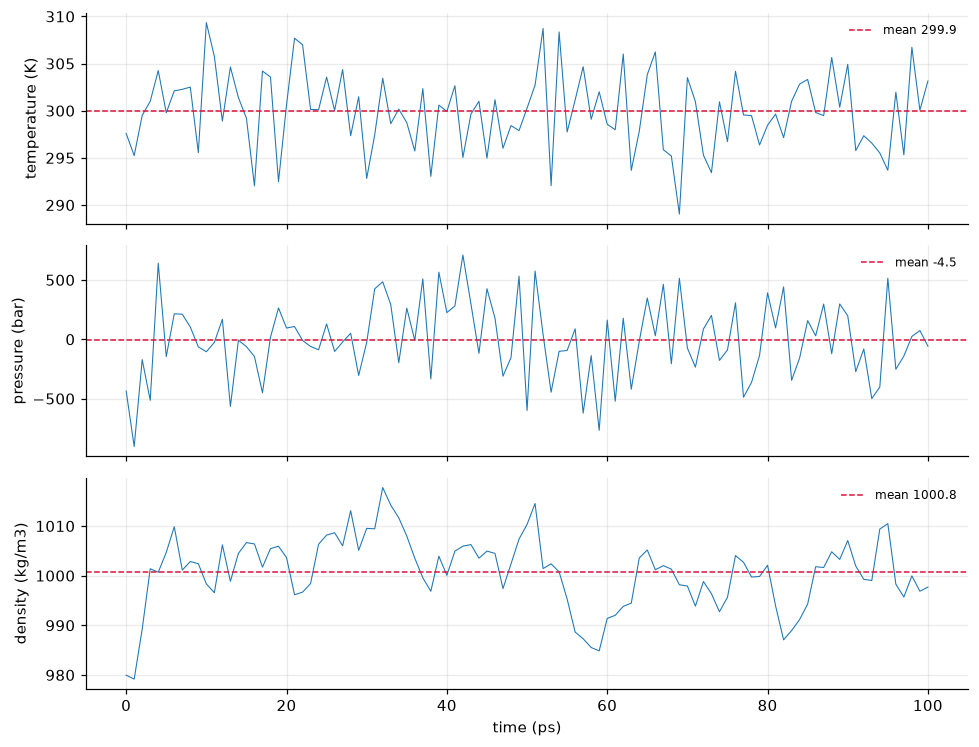

In [21]:
if not DRY_RUN and (md_dir / 'npt.edr').exists():
    traces = protocol.equilibration_report()
    labels = {'temperature': 'temperature (K)',
              'pressure': 'pressure (bar)',
              'density': 'density (kg/m3)'}
    available = [(k, v) for k, v in traces.items() if v is not None]
    fig, axes = plt.subplots(len(available), 1, figsize=(9, 2.3 * len(available)),
                             sharex=True, squeeze=False)
    for ax, (name, arr) in zip(axes[:, 0], available):
        ax.plot(arr[:, 0], arr[:, 1], lw=0.7)
        ax.set_ylabel(labels.get(name, name))
        ax.axhline(np.mean(arr[:, 1]), color='crimson', ls='--', lw=1,
                   label=f'mean {np.mean(arr[:, 1]):.1f}')
        ax.legend(fontsize=8)
    axes[-1, 0].set_xlabel('time (ps)')
    plt.tight_layout(); plt.show()
else:
    print('no npt.edr yet (dry run, or equilibration not finished)')

## 4. Production metadynamics

`HILLS` is created empty first, because the generated `plumed.dat` contains `RESTART`
and PLUMED refuses to start if the file it is told to resume from does not exist.

The run is detached. It writes checkpoints, so if it is killed you can resume with
`from_checkpoint=True` &mdash; and because `RESTART` is set, PLUMED picks the
accumulated bias back up from `HILLS` rather than starting over.

In [22]:
print(f'production length: {project.production_ns} ns = '
      f'{ns_to_steps(project.production_ns, project.dt):,} steps at {project.dt * 1000} fs')

production length: 100.0 ns = 50,000,000 steps at 2.0 fs


In [ ]:
md_job = None
if DRY_RUN:
    print('GROMACS is unavailable; showing the commands without running them.')
    protocol.production(plumed='plumed.dat', background=False)
elif not HAVE_PLUMED or not HAVE_PLUMED_PYTORCH:
    print('Skipping production: it needs PLUMED with PYTORCH_MODEL enabled.')
else:
    md_job = protocol.production(
        plumed='plumed.dat',
        background=True,
        ntmpi=1,
        ntomp=OMP_THREADS,
        gpu_id=GPU_ID,
    )
    print(md_job.status())

In [24]:
import shlex
import shutil
import subprocess

TMUX_SESSION = "asmsa_md"

if not shutil.which("tmux"):
    raise RuntimeError("tmux is not installed or is not on PATH on the remote host.")

if "md_job" in globals() and md_job is not None and md_job.running:
    print("A production run is already active; not starting a duplicate.")
elif DRY_RUN:
    print("GROMACS is unavailable; cannot start production.")
elif not HAVE_PLUMED or not HAVE_PLUMED_PYTORCH:
    print("Skipping production: it needs PLUMED with PYTORCH_MODEL enabled.")
else:
    session_exists = subprocess.run(
        ["tmux", "has-session", "-t", TMUX_SESSION],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
        check=False,
    ).returncode == 0

    if session_exists:
        print(f"tmux session {TMUX_SESSION!r} already exists; not starting a duplicate.")
        print(f"Reconnect with: tmux attach -t {TMUX_SESSION}")
    else:
        hills = protocol.state.path("HILLS")
        if not hills.exists():
            hills.touch()
            print("Created empty HILLS (plumed.dat uses RESTART).")

        if not protocol.state.exists("md.tpr") or protocol.force:
            protocol.gmx.grompp(
                f="md.mdp",
                c="npt.gro",
                t="npt.cpt",
                p=protocol.full_top,
                o="md.tpr",
                maxwarn=2,
            )
        else:
            print("  [skip] grompp: md.tpr already exists")

        workdir = protocol.workdir
        log_path = workdir / "logs" / "gmx-mdrun.log"
        log_path.parent.mkdir(parents=True, exist_ok=True)

        command = [
            protocol.gmx.gmx, "mdrun",
            "-deffnm", "md",
            "-plumed", "plumed.dat",
            "-ntmpi", "1",
            "-ntomp", str(OMP_THREADS),
        ]
        if GPU_ID is not None:
            command += ["-gpu_id", str(GPU_ID)]

        shell_command = (
            f"cd {shlex.quote(str(workdir))} && "
            f"exec {shlex.join(command)} "
            f">> {shlex.quote(str(log_path))} 2>&1"
        )

        subprocess.run(
            ["tmux", "new-session", "-d", "-s", TMUX_SESSION, shell_command],
            check=True,
        )

        print(f"Started GROMACS in tmux session {TMUX_SESSION!r}.")
        print(f"Log: {log_path}")
        print(f"Reconnect with: tmux attach -t {TMUX_SESSION}")
        print("Detach without stopping the run: Ctrl-b, then d.")

Created empty HILLS (plumed.dat uses RESTART).
$ gmx grompp -f md.mdp -c npt.gro -p trpcage-full.top -o md.tpr -t npt.cpt -maxwarn 2   [log: gmx-grompp-1793454900.log]
Started GROMACS in tmux session 'asmsa_md'.
Log: /home/tedeschg/prj/ASMSA_v2/notebooks/run/04-md/logs/gmx-mdrun.log
Reconnect with: tmux attach -t asmsa_md
Detach without stopping the run: Ctrl-b, then d.


tmux has-session -t asmsa_md && echo "tmux session is alive"
tail -n 20 /home/tedeschg/prj/ASMSA_v2/notebooks/run/04-md/logs/gmx-mdrun.log

In [25]:
# Re-run this cell to check progress. The analysis sections below work on the
# partial trajectory while the simulation is still running.
if md_job is not None:
    print(md_job.status())
    print(md_job.log(tail=20))

NameError: name 'md_job' is not defined

In [ ]:
# Extend a finished run, then restart it from its checkpoint.
# protocol.extend(additional_ns=100.0)
# md_job = protocol.production(plumed='plumed.dat', from_checkpoint=True,
#                              background=True, ntomp=OMP_THREADS)

# Stop a run early (it can be resumed from the checkpoint afterwards).
# if md_job is not None: md_job.kill()

### Reproducing this outside the notebook

Every command issued above, as a shell script &mdash; paste it into a cluster job
instead of re-running the notebook.

In [ ]:
print(gmx.script())

---
## 5. Analysis

Everything below works on a partial trajectory, so run it while the simulation
continues. It also works on `COLVAR`/`HILLS` files produced elsewhere &mdash; just point
the paths at them.

In [ ]:
colvar_path = md_dir / 'COLVAR'
hills_path = md_dir / 'HILLS'

if not colvar_path.exists():
    print(f'No {colvar_path.name} yet. PLUMED writes it during the biased run.')
    print('If you ran the simulation elsewhere, copy COLVAR and HILLS into:')
    print(f'  {md_dir}')
    colvar = None
else:
    colvar = read_colvar(colvar_path)
    cv_cols = [c for c in colvar.columns if c.startswith('model.node-')]
    print(f'{len(colvar)} records, columns: {list(colvar.columns)}')
    colvar.head()

### CV exploration over time

**What to look for:** the CVs should *roam*. Well-tempered metadynamics fills basins and
pushes the system out of them, so a CV trace that stays in one region means the bias is
not yet large enough &mdash; run longer, or raise `HEIGHT`/lower `PACE`.

Conversely, a CV that leaves the grid range (dashed lines) will crash the simulation;
that is what the generous grid margin in [05-plumed](05-plumed.ipynb) protects against.

In [ ]:
if colvar is not None:
    fig, axes = plt.subplots(len(cv_cols) + 1, 1,
                             figsize=(10, 2.0 * (len(cv_cols) + 1)), sharex=True)
    t = colvar['time'].to_numpy() / 1000.0   # ps -> ns
    for ax, col in zip(axes, cv_cols):
        ax.plot(t, colvar[col], lw=0.5)
        ax.set_ylabel(col)
    bias_col = next(c for c in colvar.columns if c.endswith('.bias'))
    axes[-1].plot(t, colvar[bias_col], lw=0.7, color='crimson')
    axes[-1].set_ylabel('bias (kJ/mol)')
    axes[-1].set_xlabel('time (ns)')
    plt.tight_layout(); plt.show()

### Free energy by reweighting

The biased trajectory is reweighted back to the unbiased ensemble: a frame at CV value
`s` and time `t` carries weight `exp(beta*(V(s,t) - c(t)))`, where `c(t)` is what
`CALC_RCT` recorded (Tiwary & Parrinello, JPC B 119, 736 (2015)).

This needs no PLUMED executable, and it can reweight onto *any* observable, not just the
biased CVs.

**What to look for:** basins separated by barriers of a few kT. The first 10&ndash;20% of
the trajectory is discarded because the early bias is far from converged. The effective
sample size tells you how much of the trajectory the reweighting actually relies on: if
it is a tiny fraction of the frames, the surface rests on very few structures and should
not be trusted.

In [ ]:
if colvar is not None:
    DISCARD = 0.2       # drop the first 20% as transient
    weights = reweight_weights(colvar, temperature=project.temperature,
                               discard_fraction=DISCARD)
    ess = 1.0 / np.sum(weights ** 2)
    print(f'effective sample size: {ess:.0f} of {len(weights)} frames '
          f'({100 * ess / len(weights):.1f}%)')

    cv = colvar[cv_cols].to_numpy()
    if len(cv_cols) >= 2:
        x, y, fe = reweight_fes(cv[:, :2], weights, bins=70,
                                temperature=project.temperature,
                                in_kT=True, max_fe=8.0)
        asmsa.viz.fes_plot(x, y, fe, label='FE / kT',
                           title=f'reweighted FES  (ESS {ess:.0f})')
    else:
        centers, fe = reweight_fes(cv[:, 0], weights,
                                   temperature=project.temperature, in_kT=True)
        plt.plot(centers, fe); plt.xlabel(cv_cols[0]); plt.ylabel('FE / kT')
    plt.tight_layout(); plt.show()

### Free energy by summing the hills

An independent estimate, from the deposited bias rather than from the trajectory.
Requires the `plumed` executable.

**Two independent estimates agreeing is the strongest evidence of convergence** there
is here. If reweighting and `sum_hills` disagree about where the basins are or how deep
they are, the run is not converged, whatever either surface looks like on its own.

In [ ]:
fes_files = []
if hills_path.exists() and HAVE_PLUMED:
    try:
        fes_files = sum_hills(
            hills_path, out_dir=md_dir / 'fes',
            stride=20,                              # intermediate surfaces
            kt_value=kT(project.temperature),
            mintozero=True,
        )
        print(f'{len(fes_files)} surfaces written')
    except Exception as exc:
        print('sum_hills failed:', exc)
else:
    print('sum_hills needs HILLS and the plumed executable;',
          'the reweighted surface above is an alternative that needs neither.')

In [ ]:
from asmsa_v2.md import read_fes_grid

if fes_files:
    final = read_fes_grid(fes_files[-1])
    if len(final) == 3:
        gx, gy, gfe = final
        gfe = gfe - np.nanmin(gfe)
        asmsa.viz.fes_plot(gx, gy, gfe, label='FE (kJ/mol)',
                           title='FES from sum_hills')
    else:
        gx, gfe = final
        plt.plot(gx, gfe - np.nanmin(gfe))
        plt.xlabel('CV 1'); plt.ylabel('FE (kJ/mol)')
    plt.tight_layout(); plt.show()

### Convergence

**What to look for:** both curves flattening.

- The **FES deviation** from the final surface should fall towards zero and stay there.
  Still descending at the end means not converged &mdash; extend the run.
- The **hill height** should decay. In well-tempered metadynamics it shrinks as basins
  fill; heights still near their initial value mean the system is still finding new
  territory.

Reading this wrong is the most common way a metadynamics study reports a free energy
that simply is not converged.

In [ ]:
dev = fes_convergence(fes_files) if len(fes_files) > 2 else None
heights = hill_height_decay(hills_path) if hills_path.exists() else None
if heights is not None and len(heights) == 0:
    heights = None

if dev is not None or heights is not None:
    asmsa.viz.convergence_plot(fes_deviation=dev, hill_heights=heights)
    plt.tight_layout(); plt.show()
else:
    print('not enough data yet for a convergence check')

## 6. Where did the simulation actually go?

Re-featurize the biased trajectory through the exported CV model and overlay it on the
frames the model was *trained* on.

**What to look for:** the metadynamics run should cover the training region **and**
extend beyond it &mdash; that extension is the new sampling you paid for. If it never
leaves the training region, the bias is too weak. If it leaves immediately and never
comes back, the CVs may be driving the system into unphysical states; check the
structures in [07-analysis](07-analysis.ipynb).

In [ ]:
import mdtraj as mdt

traj_file = md_dir / 'md.xtc'
z_md = None
if traj_file.exists() and not DRY_RUN:
    fitted = protocol.postprocess_trajectory(traj='md.xtc', out='fit.xtc')
    ref = md_dir / f'{project.name}-box.gro'
    tr_md = mdt.load(str(md_dir / fitted), top=str(ref))
    # keep only the atoms the CV is defined on, in the featurizer's order
    heavy = tr_md.top.select('element != H')
    tr_md = tr_md.atom_slice(heavy)
    print(f'{tr_md.n_frames} frames, {tr_md.n_atoms} atoms after removing hydrogens')

    batch_cv = torch.jit.load(str(md_dir / f'{project.cv_stem}-batch.pt'))
    batch_cv.eval()
    with torch.no_grad():
        z_md = batch_cv(torch.as_tensor(tr_md.xyz, dtype=torch.float32)).numpy()
    np.save(md_dir / 'latent-md.npy', z_md)
    print('latent shape:', z_md.shape)
else:
    print('no md.xtc yet')

In [ ]:
latent_file = project.dir('models') / f'latent-{project.model_name}.npy'
if z_md is not None and latent_file.exists():
    z_train = np.load(latent_file)
    fig, ax = plt.subplots(figsize=(6, 5.6))
    ax.scatter(z_train[:, 0], z_train[:, 1], s=3, alpha=0.2,
               label='training trajectory')
    ax.scatter(z_md[:, 0], z_md[:, 1], s=3, alpha=0.3, c='crimson',
               label='metadynamics')
    ax.legend(fontsize=9, markerscale=3)
    ax.set_title('new sampling obtained by biasing the learned CVs')
    asmsa.viz.latent_axes(ax)
    plt.tight_layout(); plt.show()

---

&#8592; [PLUMED export](05-plumed.ipynb) &nbsp;|&nbsp; **Next: [Analysis](07-analysis.ipynb)** &#8594;